# 2. Genre: do some genres return more than films of the same budget?

**Method.** A genre's statistic is the mean return of its films (a film counts in every genre it has).

**Compared to what?** 10,000 shuffles that swap returns only between films in the same budget decile, so a cheap genre can't win by being cheap. Holm correction over the 18 genres.

**Checks.** Other shuffles, ranks, TMDB as a second source, and Horror subgenres from two independent labels.

**What it misses.** It can't separate a genre from the companies that specialise in it. It isn't causal.

The long version, with every check, is `archive/notebooks/q1_genre.ipynb`.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").exists())
A = ROOT / "src" / "analysis"
pd.set_option("display.max_colwidth", 90)

## Main test

In [2]:
g = pd.read_csv(A / "genre/outputs/genre_shuffle.csv")
m = g.query("set == 'usable_money' and outcome == 'ln_ratio' and null == 'budget'").sort_values("excess", ascending=False)
m[["genre", "n_films", "mean", "null_lo95", "null_hi95", "excess", "p_holm"]].round(3)

,genre,n_films,mean,null_lo95,null_hi95,excess,p_holm
20,Animation,358,0.949,0.518,0.745,0.316,0.002
25,Family,368,0.814,0.426,0.668,0.266,0.002
28,Horror,816,0.826,0.524,0.722,0.203,0.003
29,Music,214,0.666,0.343,0.734,0.124,0.844
31,Romance,1001,0.608,0.452,0.612,0.076,0.419
22,Comedy,2490,0.611,0.511,0.596,0.058,0.059
19,Adventure,1345,0.667,0.573,0.678,0.042,0.585
34,Thriller,1069,0.619,0.499,0.656,0.041,0.933
30,Mystery,731,0.600,0.464,0.665,0.034,1.000
33,Sport,171,0.547,0.315,0.734,0.022,1.000


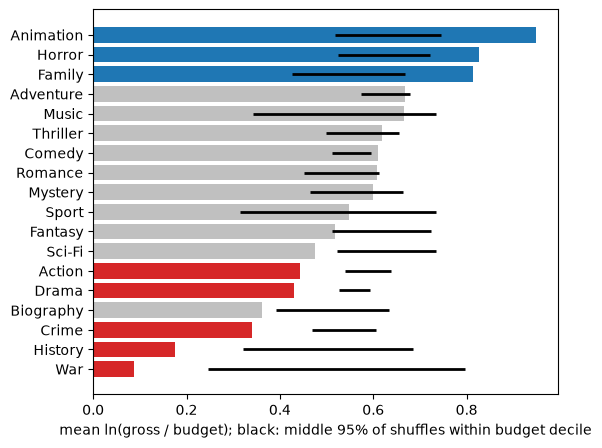

In [3]:
o = m.sort_values("mean").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(6, 5))
col = ["tab:blue" if (p < .05 and e > 0) else "tab:red" if p < .05 else "silver" for p, e in zip(o.p_holm, o.excess)]
ax.barh(o.genre, o["mean"], color=col)
ax.hlines(range(len(o)), o.null_lo95, o.null_hi95, color="k", lw=2)
ax.set_xlabel("mean ln(gross / budget); black: middle 95% of shuffles within budget decile"); plt.show()

## Does the result depend on the null?

Which shuffles each genre passes after Holm correction, on the 6,346 films. `+` is above, `-` is below, empty is inside.

In [4]:
x = g[(g.set == "usable_money")].assign(sign=lambda d: (d.excess > 0).map({True: "+", False: "-"}).where(d.p_holm < .05, ""))
x.assign(run=x.outcome + " / " + x.null).pivot(index="genre", columns="run", values="sign")

run,ln_ratio / budget,ln_ratio / budget_era,ln_ratio / budget_fine,ln_ratio / none,rank / budget
genre,,,,,
Action,-,-,-,-,-
Adventure,,,,,+
Animation,+,+,+,+,+
Biography,,,,-,-
Comedy,,,,,+
Crime,-,-,-,-,-
Drama,-,-,-,-,-
Family,+,+,+,+,+
Fantasy,,,,,


## How much does genre explain?

In [5]:
s = json.loads((A / "genre/outputs/summary.json").read_text())["sets"]
{k: {a: b for a, b in v.items() if not isinstance(b, (dict, list))} for k, v in s.items()}

{'usable_money': {'films': 6346,
  'films_with_no_kept_genre': 14,
  'mean_genres_per_film': 2.61,
  'all_film_mean_ln_ratio': 0.5729,
  'r2_budget_era': 0.0634,
  'r2_budget_era_genre': 0.0959,
  'r2_added_by_genre': 0.0324,
  'adj_r2_added_by_genre': 0.0299,
  'spearman_ols_vs_shuffle_excess': 0.934},
 'in_common_set': {'films': 1598,
  'films_with_no_kept_genre': 0,
  'mean_genres_per_film': 2.45,
  'all_film_mean_ln_ratio': 1.0047,
  'r2_budget_era': 0.1292,
  'r2_budget_era_genre': 0.1553,
  'r2_added_by_genre': 0.026,
  'adj_r2_added_by_genre': 0.0197,
  'spearman_ols_vs_shuffle_excess': 0.741}}

## Inside Horror: two labels made in different ways

TMDB keywords (list fixed before looking) and Wikidata's genres, against other Horror films of the same budget and era.

In [6]:
pd.read_csv(A / "genre/outputs/tmdb/horror_subgenres.csv").round(3)

,run,subgenre,n_films,mean,excess,z,p_holm,mean_other_horror,median,median_other_horror,share_beating_other_horror_median
0,Horror subgenre (return net of budget and era),supernatural,231,0.831,0.602,6.37,0.000,-0.008,0.900,0.224,0.697
1,Horror subgenre (return net of budget and era),slasher,166,0.511,0.288,2.30,0.022,0.158,0.658,0.313,0.627
2,Horror subgenre (return net of budget and era),found footage,50,1.604,1.480,5.09,0.000,0.140,1.742,0.353,0.780
3,Horror subgenre (return net of budget and era),creature,202,-0.106,-0.321,-3.28,0.003,0.340,0.250,0.478,0.436


In [7]:
pd.read_csv(A / "genre/outputs/categories/wikidata_horror_subgenres.csv").round(3)

,run,category,films,mean,excess,z,p_holm,median,median_other_horror
0,"Wikidata horror subgenre, inside IMDb Horror",comedy horror film,42.0,-0.083,-0.291,-1.11,1.000,0.213,0.434
1,"Wikidata horror subgenre, inside IMDb Horror",psychological horror film,29.0,0.597,0.327,1.07,1.000,0.267,0.418
2,"Wikidata horror subgenre, inside IMDb Horror",science fiction horror film,58.0,0.206,-0.036,-0.19,1.000,0.501,0.411
3,"Wikidata horror subgenre, inside IMDb Horror",slasher film,146.0,0.386,0.172,1.29,0.975,0.527,0.384
4,"Wikidata horror subgenre, inside IMDb Horror",splatter film,51.0,0.174,-0.005,-0.02,1.000,0.466,0.414
5,"Wikidata horror subgenre, inside IMDb Horror",supernatural horror film,72.0,0.993,0.740,3.96,0.002,0.985,0.364


## A third view: categories from a keyword network

Keywords linked when they share more films than a curveball null expects, grouped with Louvain.

In [8]:
pd.read_csv(A / "genre/outputs/categories/keyword_category_tests.csv").sort_values("excess", ascending=False).round(3)

,run,category,films,mean,excess,z,p_holm
2,keyword category (weighted by share of a film's keywords),3: supernatural horror,421.7,1.032,0.316,6.79,0.001
13,keyword category (weighted by share of a film's keywords),14: baby,34.7,0.934,0.238,1.52,0.903
9,keyword category (weighted by share of a film's keywords),10: villain,322.4,0.917,0.205,5.18,0.001
10,keyword category (weighted by share of a film's keywords),11: satire,178.5,0.721,0.061,0.86,1.000
11,keyword category (weighted by share of a film's keywords),12: holiday,55.7,0.696,0.056,0.47,1.000
0,keyword category (weighted by share of a film's keywords),1: mother daughter relationship,861.7,0.721,0.056,1.90,0.463
8,keyword category (weighted by share of a film's keywords),9: high school,333.1,0.724,0.026,0.52,1.000
4,keyword category (weighted by share of a film's keywords),5: murder,498.6,0.643,-0.050,-1.24,1.000
6,keyword category (weighted by share of a film's keywords),7: good versus evil,201.3,0.614,-0.076,-1.50,0.903
12,keyword category (weighted by share of a film's keywords),13: hospital,53.3,0.549,-0.091,-0.83,1.000
